# ACC 380K — Notebook 9
## Grouped evidence: totals, averages, and plots

**Notebook version 0.9.0 · October 14, 2026**

**The question:** How busy are Starbucks's US stores, and how much did COVID-19 change that?

You will answer it with one file: estimated visits to every US Starbucks store, week by week, for almost ten years. First you compare an average store-week in the year before and the year after March 2020. Then `groupby` turns 7.9 million store-weeks into one row per state, per week, or per month, and a line chart shows how visits changed over time. A total and an average answer different questions, and choosing the right one is most of the work. Companies report the same idea as sales per store, so that opening more stores does not look like busier stores.

In Colab, choose **File → Save a copy in Drive** and work in your own copy.


## 12:30 Section — live class record

This copy began from **Starter**. Nick edits it during the 12:30 class and saves it at the end. Use Starter when you want a fresh copy of the exercise.


## What you should be able to do

- Download the Starbucks weeks and turn the week text into a date column, `DATE_RANGE_START_dt`.
- Average a column over the rows you keep, joining conditions with `&` and `|`.
- Use `groupby` with `.mean()` or `.sum()` to make one row per state, per week, or per month, and `.reset_index()` to turn the groups back into columns.
- Tell a total from an average, and say which one compares states fairly.
- Take the month out of a date with `.dt.month`.
- Draw a line chart with `.plot()`, and use an AI assistant to explore other kinds of charts.

Exercises 1–4 each have a **Your turn** box: try it on your own or with your table. Run your work cell, then the collapsed **Check your work** cell below it. A line that starts with `NOT YET` tells you what to fix; revise your work cell and rerun both cells. Exercise 5 has no check.

**Read → Predict → Run → Assess → Test**


## Download the class data

The file is weekly foot-traffic estimates for every US Starbucks store, from January 2017 to September 2026. A count is the vendor's estimate of visits, not a till receipt. Run the four cells below in order. In the second one, paste the **class code** from Canvas between the quotes in `CLASS_KEY`. Do not share the code.

- `!` runs a command outside Python. `curl` saves the file as `SBUX_main.feather`. `-H` sends the class code, and `{CLASS_KEY}` puts in your code. The file is 643.5 MB.
- `pd.read_feather` reads it into `sbux`. The table uses about 3.8 GB. Standard Colab has about 12 GB.
- The last cell shows the first and last rows of `sbux`.

A wrong or missing code gets **403** and the text `Forbidden: check the class code from Canvas.`, which `curl` saves in place of the data. `pd.read_feather` then stops because the file is not a Feather file. Check the code and run the download cell again. If the runtime is deleted, run these cells again to download a new copy.


In [1]:
import pandas as pd


In [2]:
CLASS_KEY = "acc380k-8d64f3"  # paste the class code from Canvas
!curl -H "X-Class-Key: {CLASS_KEY}" -o SBUX_main.feather https://acc380k-data.nicholashallman.workers.dev/data/SBUX_main.feather


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  613M  100  613M    0     0  27.8M      0  0:00:22  0:00:22 --:--:-- 24.8M


In [3]:
sbux = pd.read_feather("SBUX_main.feather")


In [4]:
sbux


,PERSISTENT_ID_STORE,DATE_RANGE_START,STREET_ADDRESS,CITY,REGION,POSTAL_CODE,POI_CBG,LATITUDE,LONGITUDE,VISITOR_COUNTS,VISIT_COUNTS,VISITS_BY_DAY,DWELL_LT5,DWELL_5_20,DWELL_21_60,DWELL_61_240,DWELL_GT240,DEVICE_ANDROID,DEVICE_IOS
0,1251619,01/02/2017,560 North Center Street,Casper,WY,82601,560250002002,42.856172,-106.325454,701,776,"[106,206,129,77,153,52,53]",776.0,0.0,0.0,0.0,0.0,415.0,286.0
1,1251341,01/02/2017,20620 Homestead Road,Cupertino,CA,95014,060855078053,37.336156,-122.034738,8487,10312,"[1372,1263,1209,1490,1427,1858,1692]",4002.0,3608.0,2054.0,311.0,338.0,6982.0,1505.0
2,1251091,01/02/2017,24401 Brazos Town Crossing,Rosenberg,TX,77471-6268,481576755021,29.541476,-95.750728,10330,11574,"[2006,1237,1235,1465,1453,2408,1772]",7465.0,2524.0,1041.0,207.0,337.0,8435.0,1895.0
3,1253766,01/02/2017,737 Albany Shaker Road,Albany,NY,12211-1000,360010137031,42.745609,-73.809476,16767,18820,"[2586,2320,2675,3058,2447,2957,2777]",10303.0,4208.0,1898.0,1013.0,1397.0,12199.0,4568.0
4,1249983,01/02/2017,1425 West Granada Boulevard,Ormond Beach,FL,32174-8113,121270808061,29.260621,-81.110167,3504,4177,"[554,773,489,617,561,602,582]",2563.0,626.0,260.0,233.0,494.0,1661.0,1843.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7901294,1259229,09/28/2026,15970 South Mur Len Road,Olathe,KS,66062-8300,200910535591,38.839161,-94.781730,13848,18319,"[1974,2422,2470,1918,3094,3389,3053]",11813.0,5313.0,799.0,324.0,70.0,6562.0,7286.0
7901295,2544177,09/28/2026,7876 Valley View Street,Buena Park,CA,90620,060591103012,33.848013,-118.028094,3290,3754,"[420,433,472,502,700,632,595]",2818.0,0.0,936.0,0.0,0.0,2467.0,823.0
7901296,1253183,09/28/2026,6705 Camino Arroyo,Gilroy,CA,95020,060855126021,36.999801,-121.554692,10085,11830,"[1143,1182,1259,1249,2355,2144,2498]",3748.0,4655.0,2426.0,681.0,320.0,6558.0,3527.0
7901297,1260570,09/28/2026,2504 South Reserve Street,Missoula,MT,59801-7546,300630010013,46.848523,-114.038871,2236,2236,"[274,276,285,305,404,356,337]",2046.0,190.0,0.0,0.0,0.0,808.0,1428.0


One row is one **store-week**: one store in one week. `VISIT_COUNTS` is that store's estimated visits that week. **Predict:** which columns will Pandas read as numbers, and which as text?


In [ ]:
sbux.dtypes


,0
PERSISTENT_ID_STORE,int32
DATE_RANGE_START,object
STREET_ADDRESS,object
CITY,object
REGION,object
POSTAL_CODE,object
POI_CBG,object
LATITUDE,float64
LONGITUDE,float64
VISITOR_COUNTS,int32


`PERSISTENT_ID_STORE` is `int32`, a whole-number label for each store. Address, city, state (`REGION`), ZIP, census block, `VISITS_BY_DAY`, and `DATE_RANGE_START` are `object` (text). `VISITS_BY_DAY` is seven daily visit counts, Monday through Sunday, written like `[106,206,129,77,153,52,53]`; leave it as text. `VISIT_COUNTS` is `int32` and is filled in for every store-week; it is the column this notebook uses. Some other count columns are `float64` because some of their values are missing (`NaN`), and a whole-number column cannot hold `NaN`.


## Turn the week text into dates

`DATE_RANGE_START` is the Monday each week starts, written as text, month/day/year: `03/02/2020` means March 2, 2020. Text is not a date, so Python cannot tell which week comes first. `pd.to_datetime` reads the text as dates. When the text is written the US way, month first, Pandas reads it correctly on its own.

Files from elsewhere may write dates another way. Then add `format=`, which spells out the layout: `%m` is the month, `%d` the day, `%Y` the four-digit year, and `%b` a short month name such as `Mar`.

| Text in the file | Means | What to add |
|---|---|---|
| `03/02/2020` (US style, month first) | March 2, 2020 | Nothing. Pandas guesses month first, which is right. |
| `02/03/2020` (day first) | March 2, 2020 | `format="%d/%m/%Y"` or `dayfirst=True`. Without one, Pandas reads February 3. |
| `Mar 2, 2020` or `20200302` | March 2, 2020 | Spell out the layout, such as `format="%b %d, %Y"` or `format="%Y%m%d"`, so Pandas does not have to guess. |
| `2020-03-02` (ISO, year first) | March 2, 2020 | Never needed. |

The cell below keeps the original column and puts the dates in a new column, `DATE_RANGE_START_dt` (`_dt` for date-time), then shows the two side by side. **Predict:** will they look different?


In [5]:
sbux["DATE_RANGE_START_dt"] = pd.to_datetime(sbux["DATE_RANGE_START"])

In [6]:
sbux[["DATE_RANGE_START", "DATE_RANGE_START_dt"]]


,DATE_RANGE_START,DATE_RANGE_START_dt
0,01/02/2017,2017-01-02
1,01/02/2017,2017-01-02
2,01/02/2017,2017-01-02
3,01/02/2017,2017-01-02
4,01/02/2017,2017-01-02
...,...,...
7901294,09/28/2026,2026-09-28
7901295,09/28/2026,2026-09-28
7901296,09/28/2026,2026-09-28
7901297,09/28/2026,2026-09-28


In [7]:
sbux[["DATE_RANGE_START", "DATE_RANGE_START_dt"]].dtypes


,0
DATE_RANGE_START,object
DATE_RANGE_START_dt,datetime64[ns]


In [8]:
sbux.head(2)

,PERSISTENT_ID_STORE,DATE_RANGE_START,STREET_ADDRESS,CITY,REGION,POSTAL_CODE,POI_CBG,LATITUDE,LONGITUDE,VISITOR_COUNTS,VISIT_COUNTS,VISITS_BY_DAY,DWELL_LT5,DWELL_5_20,DWELL_21_60,DWELL_61_240,DWELL_GT240,DEVICE_ANDROID,DEVICE_IOS,DATE_RANGE_START_dt
0,1251619,01/02/2017,560 North Center Street,Casper,WY,82601,560250002002,42.856172,-106.325454,701,776,"[106,206,129,77,153,52,53]",776.0,0.0,0.0,0.0,0.0,415.0,286.0,2017-01-02
1,1251341,01/02/2017,20620 Homestead Road,Cupertino,CA,95014,060855078053,37.336156,-122.034738,8487,10312,"[1372,1263,1209,1490,1427,1858,1692]",4002.0,3608.0,2054.0,311.0,338.0,6982.0,1505.0,2017-01-02


In [9]:
sbux.loc[sbux['REGION'] == "TX"]

,PERSISTENT_ID_STORE,DATE_RANGE_START,STREET_ADDRESS,CITY,REGION,POSTAL_CODE,POI_CBG,LATITUDE,LONGITUDE,VISITOR_COUNTS,VISIT_COUNTS,VISITS_BY_DAY,DWELL_LT5,DWELL_5_20,DWELL_21_60,DWELL_61_240,DWELL_GT240,DEVICE_ANDROID,DEVICE_IOS,DATE_RANGE_START_dt
2,1251091,01/02/2017,24401 Brazos Town Crossing,Rosenberg,TX,77471-6268,481576755021,29.541476,-95.750728,10330,11574,"[2006,1237,1235,1465,1453,2408,1772]",7465.0,2524.0,1041.0,207.0,337.0,8435.0,1895.0,2017-01-02
12,2544089,01/02/2017,920 East Northwest Highway,Grapevine,TX,76051,484391137123,32.940551,-97.066449,3919,4372,"[449,567,514,899,969,471,502]",3517.0,260.0,311.0,233.0,51.0,2050.0,1869.0,2017-01-02
31,2547842,01/02/2017,901 Long Prairie Road,Flower Mound,TX,75022,481210217562,32.995403,-97.064921,3815,4225,"[501,670,463,719,714,602,555]",2954.0,570.0,363.0,288.0,51.0,1505.0,2310.0,2017-01-02
33,1259481,01/02/2017,633 West Wheatland,Duncanville,TX,75116-4517,481130165182,32.648272,-96.922798,8254,10752,"[1900,1572,1338,1413,1478,1623,1428]",4648.0,3766.0,1402.0,311.0,624.0,6671.0,1583.0,2017-01-02
41,5429267,01/02/2017,8532 Davis Boulevard,North Richland Hills,TX,76182,484391136402,32.908147,-97.188618,337,338,"[79,0,51,103,25,26,53]",286.0,52.0,0.0,0.0,0.0,156.0,182.0,2017-01-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7901253,5428506,09/28/2026,3100 South Hulen Street,Ft Worth,TX,76109,484391054051,32.705955,-97.390157,6304,10269,"[1270,1201,1210,1181,1557,1759,2091]",6011.0,2272.0,1070.0,593.0,323.0,3675.0,2629.0,2026-09-28
7901258,2548233,09/28/2026,2321 West University Drive,Denton,TX,76201,481210204033,33.228362,-97.162910,1822,1823,"[215,197,216,197,236,504,258]",1106.0,717.0,0.0,0.0,0.0,1185.0,637.0,2026-09-28
7901284,5429037,09/28/2026,8520 Spring Cypress Road,Spring,TX,77379,482015548041,30.036048,-95.553309,3162,3664,"[469,473,561,541,562,662,396]",3130.0,198.0,0.0,0.0,336.0,374.0,2788.0,2026-09-28
7901285,5428733,09/28/2026,8000 Research Forest Drive,The Woodlands,TX,77381,483396906093,30.210603,-95.528339,2088,2472,"[362,335,246,403,443,316,367]",2096.0,333.0,0.0,43.0,0.0,656.0,1432.0,2026-09-28


In [10]:
sbux['VISIT_COUNTS'].mean()

np.float64(3394.0811948769438)

In [ ]:
sbux.loc[sbux['DATE_RANGE_START_dt'] >= "2026/1/1"]

,PERSISTENT_ID_STORE,DATE_RANGE_START,STREET_ADDRESS,CITY,REGION,POSTAL_CODE,POI_CBG,LATITUDE,LONGITUDE,VISITOR_COUNTS,VISIT_COUNTS,VISITS_BY_DAY,DWELL_LT5,DWELL_5_20,DWELL_21_60,DWELL_61_240,DWELL_GT240,DEVICE_ANDROID,DEVICE_IOS,DATE_RANGE_START_dt
7253069,1249759,01/05/2026,3336 Arapahoe,Erie,CO,80516-6013,080130128013,40.015767,-105.102383,1066,1175,"[165,154,154,197,164,176,165]",1144.0,31.0,0.0,0.0,0.0,313.0,753.0,2026-01-05
7253070,1252501,01/05/2026,4231 East Little Creek Road,Norfolk,VA,23518,517100066052,36.917605,-76.193658,1988,2174,"[330,297,231,296,318,439,264]",1947.0,227.0,0.0,0.0,0.0,934.0,1054.0,2026-01-05
7253071,1251179,01/05/2026,815 West 2000,Layton,UT,84041,490111258051,41.087339,-111.980861,7106,8446,"[1342,1154,1044,1107,1249,1229,1320]",6029.0,1136.0,190.0,746.0,345.0,3761.0,3345.0,2026-01-05
7253072,1255073,01/05/2026,2454 FM 2094,League City,TX,77573,481677213022,29.529083,-95.073302,3691,4370,"[528,561,583,800,625,724,550]",3762.0,461.0,147.0,0.0,0.0,1767.0,1924.0,2026-01-05
7253073,5070581,01/05/2026,5125 Jonestown Road 331,Harrisburg,PA,17112,420430226013,40.308669,-76.796022,637,670,"[66,77,77,88,88,187,88]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7901294,1259229,09/28/2026,15970 South Mur Len Road,Olathe,KS,66062-8300,200910535591,38.839161,-94.781730,13848,18319,"[1974,2422,2470,1918,3094,3389,3053]",11813.0,5313.0,799.0,324.0,70.0,6562.0,7286.0,2026-09-28
7901295,2544177,09/28/2026,7876 Valley View Street,Buena Park,CA,90620,060591103012,33.848013,-118.028094,3290,3754,"[420,433,472,502,700,632,595]",2818.0,0.0,936.0,0.0,0.0,2467.0,823.0,2026-09-28
7901296,1253183,09/28/2026,6705 Camino Arroyo,Gilroy,CA,95020,060855126021,36.999801,-121.554692,10085,11830,"[1143,1182,1259,1249,2355,2144,2498]",3748.0,4655.0,2426.0,681.0,320.0,6558.0,3527.0,2026-09-28
7901297,1260570,09/28/2026,2504 South Reserve Street,Missoula,MT,59801-7546,300630010013,46.848523,-114.038871,2236,2236,"[274,276,285,305,404,356,337]",2046.0,190.0,0.0,0.0,0.0,808.0,1428.0,2026-09-28


The same weeks, written two ways. `DATE_RANGE_START` is `object` (text); `DATE_RANGE_START_dt` is `datetime64[ns]`, a date. From here on, use `DATE_RANGE_START_dt` whenever you compare, group, or plot weeks. With it, `sbux["DATE_RANGE_START_dt"] >= "2019-03-01"` keeps the weeks on or after March 1, 2019.


## Exercise 1 — Before and after COVID-19

> **Your turn:** Work on your own or with your table before we work through this together.

Did an average store get fewer visits after COVID-19 arrived in March 2020? Compare two 12-month periods:

- **Before COVID-19:** weeks starting March 1, 2019 through February 29, 2020.
- **After COVID-19:** weeks starting March 1, 2020 through February 28, 2021.

A reminder from Notebook 8: use `&` when **both** conditions must be true and `|` when **either** one may be true, and put each condition in its own parentheses.

Make four numbers, each the average `VISIT_COUNTS` over the store-weeks you keep:

1. `visits_before_covid`: all stores, before COVID-19.
2. `visits_after_covid`: all stores, after COVID-19.
3. `pacnw_visits_before`: stores in the **Pacific Northwest**, before COVID-19. Here the Pacific Northwest means Washington or Oregon: `REGION` is `"WA"` or `"OR"`.
4. `pacnw_visits_after`: stores in the Pacific Northwest, after COVID-19.

Use `DATE_RANGE_START_dt` for the dates.

**Predict:** Did an average store-week lose about a tenth of its visits, a quarter, or a half?


In [11]:
visits_before_covid = (
    sbux.loc[
        (sbux['DATE_RANGE_START_dt'] >= "2019/3/1") &
        (sbux['DATE_RANGE_START_dt'] <= "2020/2/29"),
        'VISIT_COUNTS'
    ].mean()
)

visits_after_covid = (
    sbux.loc[
        (sbux['DATE_RANGE_START_dt'] >= "2020/3/1") &
        (sbux['DATE_RANGE_START_dt'] <= "2021/2/28"),
        'VISIT_COUNTS'
    ].mean()
)

pacnw_visits_before = (
    sbux.loc[
        (sbux['DATE_RANGE_START_dt'] >= "2019/3/1") &
        (sbux['DATE_RANGE_START_dt'] <= "2020/2/29") &
        ((sbux['REGION'] == "WA") | (sbux['REGION'] == "OR")),
        'VISIT_COUNTS'
    ].mean()
)

pacnw_visits_after = (
    sbux.loc[
        (sbux['DATE_RANGE_START_dt'] >= "2020/3/1") &
        (sbux['DATE_RANGE_START_dt'] <= "2021/2/28") &
        ((sbux['REGION'] == "WA") | (sbux['REGION'] == "OR")),
        'VISIT_COUNTS'
    ].mean()
)

In [12]:
visits_before_covid

np.float64(3645.8171412307256)

In [13]:
visits_after_covid

np.float64(2582.7267207182804)

In [ ]:
#@title Check your work { display-mode: "form" }
import math

import numpy as np
import pandas as pd

check_tally = {"passed": 0, "total": 0}


class _NotReady(Exception):
    pass


def need(name, kind=None):
    """Return the student's variable, or stop this one check with a friendly reason."""
    if name not in globals():
        raise _NotReady(name + " does not exist yet. Run your work cell first. If it stopped with an "
                        "error, read the last line of the error, fix it, and rerun the work cell.")
    value = globals()[name]
    if value is None:
        raise _NotReady(name + " is still None. Replace the starter None in your work cell.")
    if kind == "DataFrame" and not isinstance(value, pd.DataFrame):
        if isinstance(value, pd.Series):
            raise _NotReady(name + " is a Series (one column), but this exercise needs a DataFrame. "
                            'Put the column names in a list, as in .loc[rows, ["a", "b"]].')
        raise _NotReady(name + " is a " + type(value).__name__ + ", but this exercise needs a DataFrame.")
    return value


def _short(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isnan(value):
        value = round(value, 4)
    text = repr(value)
    return text if len(text) <= 160 else text[:160] + "..."


def _matches(actual, expected):
    if isinstance(expected, np.generic):
        expected = expected.item()
    if isinstance(expected, bool):
        return type(actual).__name__ in ("bool", "bool_") and bool(actual) == expected
    if isinstance(expected, float):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        number = float(actual)
        if math.isnan(expected):
            return math.isnan(number)
        return not math.isnan(number) and abs(number - expected) <= 0.005
    if isinstance(expected, list):
        if not isinstance(actual, list) or len(actual) != len(expected):
            return False
        return all(_matches(a, e) for a, e in zip(actual, expected))
    if isinstance(expected, int):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        return bool(actual == expected)
    return bool(actual == expected)


def first_difference(labels, actual, expected):
    """Return "all match", or describe the first label whose value differs."""
    actual, expected = list(actual), list(expected)
    if len(actual) != len(expected):
        return str(len(actual)) + " rows, but expected " + str(len(expected))
    for label, got, want in zip(labels, actual, expected):
        if not _matches(got, want):
            return str(label) + ": got " + _short(got) + ", expected " + _short(want)
    return "all match"


def check(case_name, get_actual, expected, hint=""):
    """Run get_actual() safely and report whether it matches expected (a value or a function)."""
    check_tally["total"] = check_tally["total"] + 1
    try:
        if callable(expected):
            expected = expected()
        actual = get_actual()
    except _NotReady as reason:
        print("NOT YET —", case_name + ":", reason)
        return
    except Exception as error:
        print("NOT YET —", case_name + ": checking raised " + type(error).__name__ + ": " + str(error)[:150])
        fallback = "Read the error, fix your work cell, and rerun it before this check."
        print("    Hint:", fallback if callable(hint) or not hint else hint)
        return
    try:
        matched = _matches(actual, expected)
    except Exception:
        matched = False
    if matched:
        check_tally["passed"] = check_tally["passed"] + 1
        print("✓", case_name, "— passed")
    else:
        print("NOT YET —", case_name + ": expected", _short(expected), "but got", _short(actual))
        if callable(hint):
            hint = hint(actual)
        if hint:
            print("    Hint:", hint)


def check_summary(label):
    """Print how many checks passed."""
    if check_tally["passed"] == check_tally["total"]:
        print(label + ": all " + str(check_tally["total"]) + " checks passed ✓")
    else:
        print(label + ": NOT YET — " + str(check_tally["passed"]) + " of " + str(check_tally["total"])
              + " checks passed. Fix the first NOT YET line, rerun your work cell, then rerun this check.")


def need_sbux():
    """Return sbux, or stop this one check if it is not loaded."""
    table = globals().get("sbux")
    if not isinstance(table, pd.DataFrame) or len(table) == 0:
        raise _NotReady("sbux is not loaded. Paste the class code from Canvas into CLASS_KEY, rerun the "
                        "download cell, then rerun your work cell.")
    return table


def _dated():
    table = need_sbux()
    if ("DATE_RANGE_START_dt" not in table.columns
            or not pd.api.types.is_datetime64_any_dtype(table["DATE_RANGE_START_dt"])):
        raise _NotReady("sbux has no DATE_RANGE_START_dt date column yet. Run the date conversion cell "
                        "(the one with pd.to_datetime), then rerun your work cell.")
    return table


def _mean(lo, hi, pacnw=False):
    table = _dated()
    keep = (table["DATE_RANGE_START_dt"] >= lo) & (table["DATE_RANGE_START_dt"] <= hi)
    if pacnw:
        keep = keep & table["REGION"].isin(["WA", "OR"])
    return float(table.loc[keep, "VISIT_COUNTS"].mean())


def _number(name):
    value = need(name)
    if isinstance(value, (pd.Series, pd.DataFrame)):
        raise _NotReady(name + " is a table, not one number. Keep only the VISIT_COUNTS column, "
                        "then take its average with .mean().")
    number = float(value)
    if math.isnan(number):
        raise _NotReady(name + " is nan, so no rows were kept. Compare DATE_RANGE_START_dt (not the "
                        "text column) and check the dates and state codes.")
    return number


check("All stores, before", lambda: _number("visits_before_covid"), lambda: _mean("2019-03-01", "2020-02-29"),
      "Keep the weeks from March 1, 2019 through February 29, 2020: two date conditions joined with &.")
check("All stores, after", lambda: _number("visits_after_covid"), lambda: _mean("2020-03-01", "2021-02-28"),
      "Same idea, for March 1, 2020 through February 28, 2021.")
check("Pacific Northwest, before", lambda: _number("pacnw_visits_before"),
      lambda: _mean("2019-03-01", "2020-02-29", pacnw=True),
      "Join the two state conditions with | inside their own parentheses, then join that with the "
      "two date conditions using &.")
check("Pacific Northwest, after", lambda: _number("pacnw_visits_after"),
      lambda: _mean("2020-03-01", "2021-02-28", pacnw=True),
      "Same state part, with the after-COVID dates.")
check_summary("Exercise 1")


✓ All stores, before — passed
✓ All stores, after — passed
✓ Pacific Northwest, before — passed
✓ Pacific Northwest, after — passed
Exercise 1: all 4 checks passed ✓


An average store-week had about 3,646 visits before COVID-19 and 2,583 after: down by more than a quarter. In the Pacific Northwest it fell less, from about 3,451 to 2,736, or about a fifth. A store's rent and most of its staff cost about the same with fewer visits, so a drop like this squeezes each store's profit margin.


## Comparing states with `groupby`

What if you wanted to compare visits across different regions? You could write a mask for each state, one at a time, but there are 51 of them (the 50 states and DC). `groupby` does them all at once, in three steps:

1. **Split** the rows into groups, one group per value of a column (here, each state in `REGION`).
2. **Apply** a calculation inside each group (here, `.mean()` of `VISIT_COUNTS`).
3. **Combine** the results into a new table with **one row per group**.

`sbux[["REGION", "VISIT_COUNTS"]]` first keeps only the two columns we need, so `.mean()` has just one column to average. At the end, `.sort_values("VISIT_COUNTS")` puts the rows in order of that column, smallest first.

**Predict:** How many rows will the result have? What does one row represent?


In [17]:
for state in ["TX", "CA"]
    sbux.loc[sbux['REGION'] == state, 'VISIT_COUNTS'].mean()

np.float64(4192.159761739657)

In [22]:
sbux[["REGION", "VISIT_COUNTS"]].groupby("REGION").mean().sort_values('VISIT_COUNTS', ascending = False)

,VISIT_COUNTS
REGION,
IA,5499.099627
AL,5437.730460
KS,5386.185798
NE,4987.176180
KY,4686.259687
WY,4570.954532
OK,4387.226228
MS,4379.573414
IN,4348.601164


In [ ]:
sbux[["REGION", "VISIT_COUNTS"]].groupby("REGION").mean().sort_values("VISIT_COUNTS")


51 rows, one per state. The input had one row per store-week; the output has one row per **state**. Each number is the average visits in one store-week in that state, so a state with many stores and a state with few are on the same scale. Vermont is at the top, with about 1,090 visits per store-week, and Iowa is at the bottom, with about 5,500. `REGION` is now the **index**: the labels down the left side, in bold, rather than an ordinary column.

To put the largest first, add `ascending=False` inside `.sort_values(...)`.


## Exercise 2 — Totals or averages?

> **Your turn:** Work on your own or with your table before we work through this together.

1. Make `state_totals`: the **total** `VISIT_COUNTS` for each `REGION` (use `.sum()` in place of `.mean()`), sorted so the largest total comes first.
2. Make `state_averages`: the **average** `VISIT_COUNTS` for each `REGION`, sorted so the largest average comes first.

Then look at the top five rows of each with `.head()`.

**Predict:** Iowa has the highest average visits per store-week. Will it also have the most total visits? If not, which state will, and why?


In [23]:
state_averages = sbux[["REGION", "VISIT_COUNTS"]].groupby("REGION").mean().sort_values("VISIT_COUNTS")

,VISIT_COUNTS
REGION,
VT,1085.353689
RI,1590.871081
DC,1628.073245
MA,1632.237392
ME,1660.042054
CT,2112.245928
DE,2167.191451
HI,2221.486018
NJ,2240.721135


In [ ]:
#@title Check your work { display-mode: "form" }
import math

import numpy as np
import pandas as pd

check_tally = {"passed": 0, "total": 0}


class _NotReady(Exception):
    pass


def need(name, kind=None):
    """Return the student's variable, or stop this one check with a friendly reason."""
    if name not in globals():
        raise _NotReady(name + " does not exist yet. Run your work cell first. If it stopped with an "
                        "error, read the last line of the error, fix it, and rerun the work cell.")
    value = globals()[name]
    if value is None:
        raise _NotReady(name + " is still None. Replace the starter None in your work cell.")
    if kind == "DataFrame" and not isinstance(value, pd.DataFrame):
        if isinstance(value, pd.Series):
            raise _NotReady(name + " is a Series (one column), but this exercise needs a DataFrame. "
                            'Put the column names in a list, as in .loc[rows, ["a", "b"]].')
        raise _NotReady(name + " is a " + type(value).__name__ + ", but this exercise needs a DataFrame.")
    return value


def _short(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isnan(value):
        value = round(value, 4)
    text = repr(value)
    return text if len(text) <= 160 else text[:160] + "..."


def _matches(actual, expected):
    if isinstance(expected, np.generic):
        expected = expected.item()
    if isinstance(expected, bool):
        return type(actual).__name__ in ("bool", "bool_") and bool(actual) == expected
    if isinstance(expected, float):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        number = float(actual)
        if math.isnan(expected):
            return math.isnan(number)
        return not math.isnan(number) and abs(number - expected) <= 0.005
    if isinstance(expected, list):
        if not isinstance(actual, list) or len(actual) != len(expected):
            return False
        return all(_matches(a, e) for a, e in zip(actual, expected))
    if isinstance(expected, int):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        return bool(actual == expected)
    return bool(actual == expected)


def first_difference(labels, actual, expected):
    """Return "all match", or describe the first label whose value differs."""
    actual, expected = list(actual), list(expected)
    if len(actual) != len(expected):
        return str(len(actual)) + " rows, but expected " + str(len(expected))
    for label, got, want in zip(labels, actual, expected):
        if not _matches(got, want):
            return str(label) + ": got " + _short(got) + ", expected " + _short(want)
    return "all match"


def check(case_name, get_actual, expected, hint=""):
    """Run get_actual() safely and report whether it matches expected (a value or a function)."""
    check_tally["total"] = check_tally["total"] + 1
    try:
        if callable(expected):
            expected = expected()
        actual = get_actual()
    except _NotReady as reason:
        print("NOT YET —", case_name + ":", reason)
        return
    except Exception as error:
        print("NOT YET —", case_name + ": checking raised " + type(error).__name__ + ": " + str(error)[:150])
        fallback = "Read the error, fix your work cell, and rerun it before this check."
        print("    Hint:", fallback if callable(hint) or not hint else hint)
        return
    try:
        matched = _matches(actual, expected)
    except Exception:
        matched = False
    if matched:
        check_tally["passed"] = check_tally["passed"] + 1
        print("✓", case_name, "— passed")
    else:
        print("NOT YET —", case_name + ": expected", _short(expected), "but got", _short(actual))
        if callable(hint):
            hint = hint(actual)
        if hint:
            print("    Hint:", hint)


def check_summary(label):
    """Print how many checks passed."""
    if check_tally["passed"] == check_tally["total"]:
        print(label + ": all " + str(check_tally["total"]) + " checks passed ✓")
    else:
        print(label + ": NOT YET — " + str(check_tally["passed"]) + " of " + str(check_tally["total"])
              + " checks passed. Fix the first NOT YET line, rerun your work cell, then rerun this check.")


def need_sbux():
    """Return sbux, or stop this one check if it is not loaded."""
    table = globals().get("sbux")
    if not isinstance(table, pd.DataFrame) or len(table) == 0:
        raise _NotReady("sbux is not loaded. Paste the class code from Canvas into CLASS_KEY, rerun the "
                        "download cell, then rerun your work cell.")
    return table


def _student(name):
    value = need(name)
    if isinstance(value, pd.DataFrame):
        if "REGION" in value.columns:
            value = value.set_index("REGION")
        if "VISIT_COUNTS" not in value.columns:
            raise _NotReady(name + " has no VISIT_COUNTS column. Keep REGION and VISIT_COUNTS before grouping.")
        value = value["VISIT_COUNTS"]
    elif not isinstance(value, pd.Series):
        raise _NotReady(name + " should be a table with one row per REGION.")
    return value


def _expected(how):
    grouped = need_sbux().groupby("REGION")["VISIT_COUNTS"]
    return grouped.sum() if how == "sum" else grouped.mean()


def _compare(name, how):
    expected = _expected(how)
    got = _student(name)
    if len(got) < len(expected):
        raise _NotReady(name + " has " + str(len(got)) + " rows, but there are " + str(len(expected))
                        + " states. Keep every state in " + name + "; use .head() only to look at it.")
    return first_difference(expected.index, got.reindex(expected.index).tolist(), expected.astype(float).tolist())


check("state_totals (each state)", lambda: _compare("state_totals", "sum"), "all match",
      "Add up VISIT_COUNTS for each REGION with .sum().")
check("state_totals, largest first", lambda: _student("state_totals").index.tolist()[:3],
      lambda: _expected("sum").sort_values(ascending=False).index.tolist()[:3],
      "Sort by VISIT_COUNTS with ascending=False.")
check("state_averages (each state)", lambda: _compare("state_averages", "mean"), "all match",
      "Average VISIT_COUNTS for each REGION with .mean().")
check("state_averages, largest first", lambda: _student("state_averages").index.tolist()[:3],
      lambda: _expected("mean").sort_values(ascending=False).index.tolist()[:3],
      "Sort by VISIT_COUNTS with ascending=False.")
check_summary("Exercise 2")


California, Texas, and Florida have the most total visits, because they have the most stores; Iowa is 24th of 51. By average visits per store-week the order changes: Iowa (about 5,500), Alabama, and Kansas lead, and California (about 3,000) is 36th of 51. A total mostly measures how many stores a state has; an average measures how busy a typical store is. When you report a state figure, name the measure: "total visits" or "average visits per store-week."


## One row per state per week

To see how each state changed over time, group by **two** columns: the state and the week. Each group is then one state in one week, and `.mean()` gives the average visits per store in that state that week. The column keeps its name, `VISIT_COUNTS`, but it now holds an average.

Grouping by two columns makes both of them the index. `.reset_index()` turns the index back into ordinary columns, so `REGION` and `DATE_RANGE_START_dt` can be used in a mask and on a chart like any other column.

**Predict:** about how many rows will `sbux_by_state_week` have? (51 states, 509 weeks.)


In [24]:
sbux

,PERSISTENT_ID_STORE,DATE_RANGE_START,STREET_ADDRESS,CITY,REGION,POSTAL_CODE,POI_CBG,LATITUDE,LONGITUDE,VISITOR_COUNTS,VISIT_COUNTS,VISITS_BY_DAY,DWELL_LT5,DWELL_5_20,DWELL_21_60,DWELL_61_240,DWELL_GT240,DEVICE_ANDROID,DEVICE_IOS,DATE_RANGE_START_dt
0,1251619,01/02/2017,560 North Center Street,Casper,WY,82601,560250002002,42.856172,-106.325454,701,776,"[106,206,129,77,153,52,53]",776.0,0.0,0.0,0.0,0.0,415.0,286.0,2017-01-02
1,1251341,01/02/2017,20620 Homestead Road,Cupertino,CA,95014,060855078053,37.336156,-122.034738,8487,10312,"[1372,1263,1209,1490,1427,1858,1692]",4002.0,3608.0,2054.0,311.0,338.0,6982.0,1505.0,2017-01-02
2,1251091,01/02/2017,24401 Brazos Town Crossing,Rosenberg,TX,77471-6268,481576755021,29.541476,-95.750728,10330,11574,"[2006,1237,1235,1465,1453,2408,1772]",7465.0,2524.0,1041.0,207.0,337.0,8435.0,1895.0,2017-01-02
3,1253766,01/02/2017,737 Albany Shaker Road,Albany,NY,12211-1000,360010137031,42.745609,-73.809476,16767,18820,"[2586,2320,2675,3058,2447,2957,2777]",10303.0,4208.0,1898.0,1013.0,1397.0,12199.0,4568.0,2017-01-02
4,1249983,01/02/2017,1425 West Granada Boulevard,Ormond Beach,FL,32174-8113,121270808061,29.260621,-81.110167,3504,4177,"[554,773,489,617,561,602,582]",2563.0,626.0,260.0,233.0,494.0,1661.0,1843.0,2017-01-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7901294,1259229,09/28/2026,15970 South Mur Len Road,Olathe,KS,66062-8300,200910535591,38.839161,-94.781730,13848,18319,"[1974,2422,2470,1918,3094,3389,3053]",11813.0,5313.0,799.0,324.0,70.0,6562.0,7286.0,2026-09-28
7901295,2544177,09/28/2026,7876 Valley View Street,Buena Park,CA,90620,060591103012,33.848013,-118.028094,3290,3754,"[420,433,472,502,700,632,595]",2818.0,0.0,936.0,0.0,0.0,2467.0,823.0,2026-09-28
7901296,1253183,09/28/2026,6705 Camino Arroyo,Gilroy,CA,95020,060855126021,36.999801,-121.554692,10085,11830,"[1143,1182,1259,1249,2355,2144,2498]",3748.0,4655.0,2426.0,681.0,320.0,6558.0,3527.0,2026-09-28
7901297,1260570,09/28/2026,2504 South Reserve Street,Missoula,MT,59801-7546,300630010013,46.848523,-114.038871,2236,2236,"[274,276,285,305,404,356,337]",2046.0,190.0,0.0,0.0,0.0,808.0,1428.0,2026-09-28


In [29]:
sbux_by_state_week = sbux[["REGION", "VISIT_COUNTS", "DATE_RANGE_START_dt"]].groupby(["REGION", "DATE_RANGE_START_dt"]).mean().reset_index()

In [30]:
sbux_by_state_week.loc[sbux_by_state_week['REGION'] == 'TX']

,REGION,DATE_RANGE_START_dt,VISIT_COUNTS
21887,TX,2017-01-02,3698.129252
21888,TX,2017-01-09,3479.363900
21889,TX,2017-01-16,3644.358180
21890,TX,2017-01-23,3689.374879
21891,TX,2017-01-30,3652.116845
...,...,...,...
22391,TX,2026-08-31,4083.845517
22392,TX,2026-09-07,3912.458305
22393,TX,2026-09-14,3926.558236
22394,TX,2026-09-21,3927.820690


In [ ]:
sbux_by_state_week = sbux[["REGION", "VISIT_COUNTS", "DATE_RANGE_START_dt"]].groupby(["REGION", "DATE_RANGE_START_dt"]).mean().reset_index()
sbux_by_state_week


In [31]:
sbux_by_state_week

,REGION,DATE_RANGE_START_dt,VISIT_COUNTS
0,AK,2017-01-02,2200.183673
1,AK,2017-01-09,2016.265306
2,AK,2017-01-16,1980.918367
3,AK,2017-01-23,2008.918367
4,AK,2017-01-30,2050.333333
...,...,...,...
25946,WY,2026-08-31,5285.678571
25947,WY,2026-09-07,5143.857143
25948,WY,2026-09-14,5104.250000
25949,WY,2026-09-21,5030.821429


25,951 rows: just under 51 × 509 = 25,959, because Vermont is missing from 8 weeks. Three ordinary columns.

## Plot one state

`.plot(x="column", y="column")` on a table draws a line chart, with one column across the bottom and one up the side. Keep California's rows with a mask, then plot the week against the average visits.


<Axes: xlabel='DATE_RANGE_START_dt'>

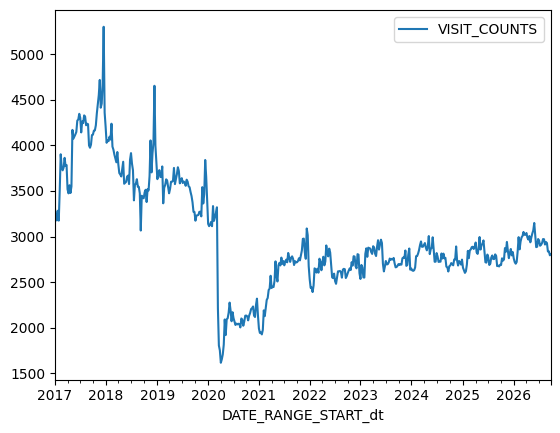

In [33]:
sbux_by_state_week.loc[sbux_by_state_week["REGION"] == "CA"].plot(x="DATE_RANGE_START_dt", y="VISIT_COUNTS")


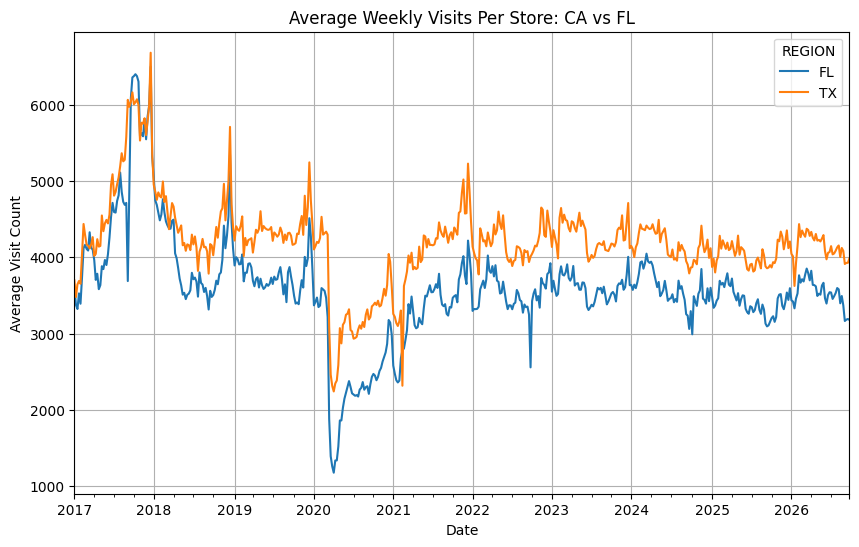

In [35]:
import matplotlib.pyplot as plt

# Filter for both California (CA) and Florida (FL)
ca_fl_data = sbux_by_state_week.loc[sbux_by_state_week["REGION"].isin(["TX", "FL"])]

# Pivot the table so that regions are columns and dates are index
pivoted_data = ca_fl_data.pivot(index="DATE_RANGE_START_dt", columns="REGION", values="VISIT_COUNTS")

# Plot the data
pivoted_data.plot(figsize=(10, 6))
plt.title("Average Weekly Visits Per Store: CA vs FL")
plt.xlabel("Date")
plt.ylabel("Average Visit Count")
plt.grid(True)
plt.show()

An average California store had about 3,530 visits a week in 2019. That fell to about 1,620 in the week of April 6, 2020, and has stayed lower since, at about 2,780 a week in 2024. To plot another state, change `"CA"` to its code.


## Exercise 3 — Weekly totals

> **Your turn:** Work on your own or with your table before we work through this together.

1. Make `weekly_visits`: the **total** `VISIT_COUNTS` for each week (`DATE_RANGE_START_dt`), for all stores together. Keep just those two columns before grouping, and use `.reset_index()` so the week is an ordinary column.
2. Make `weekly_sorted`: `weekly_visits` sorted so that the week with the **most** visits comes first.

Before running, predict how many rows `weekly_visits` will have, and which week will be the busiest.


In [ ]:
#@title Check your work { display-mode: "form" }
import math

import numpy as np
import pandas as pd

check_tally = {"passed": 0, "total": 0}


class _NotReady(Exception):
    pass


def need(name, kind=None):
    """Return the student's variable, or stop this one check with a friendly reason."""
    if name not in globals():
        raise _NotReady(name + " does not exist yet. Run your work cell first. If it stopped with an "
                        "error, read the last line of the error, fix it, and rerun the work cell.")
    value = globals()[name]
    if value is None:
        raise _NotReady(name + " is still None. Replace the starter None in your work cell.")
    if kind == "DataFrame" and not isinstance(value, pd.DataFrame):
        if isinstance(value, pd.Series):
            raise _NotReady(name + " is a Series (one column), but this exercise needs a DataFrame. "
                            'Put the column names in a list, as in .loc[rows, ["a", "b"]].')
        raise _NotReady(name + " is a " + type(value).__name__ + ", but this exercise needs a DataFrame.")
    return value


def _short(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isnan(value):
        value = round(value, 4)
    text = repr(value)
    return text if len(text) <= 160 else text[:160] + "..."


def _matches(actual, expected):
    if isinstance(expected, np.generic):
        expected = expected.item()
    if isinstance(expected, bool):
        return type(actual).__name__ in ("bool", "bool_") and bool(actual) == expected
    if isinstance(expected, float):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        number = float(actual)
        if math.isnan(expected):
            return math.isnan(number)
        return not math.isnan(number) and abs(number - expected) <= 0.005
    if isinstance(expected, list):
        if not isinstance(actual, list) or len(actual) != len(expected):
            return False
        return all(_matches(a, e) for a, e in zip(actual, expected))
    if isinstance(expected, int):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        return bool(actual == expected)
    return bool(actual == expected)


def first_difference(labels, actual, expected):
    """Return "all match", or describe the first label whose value differs."""
    actual, expected = list(actual), list(expected)
    if len(actual) != len(expected):
        return str(len(actual)) + " rows, but expected " + str(len(expected))
    for label, got, want in zip(labels, actual, expected):
        if not _matches(got, want):
            return str(label) + ": got " + _short(got) + ", expected " + _short(want)
    return "all match"


def check(case_name, get_actual, expected, hint=""):
    """Run get_actual() safely and report whether it matches expected (a value or a function)."""
    check_tally["total"] = check_tally["total"] + 1
    try:
        if callable(expected):
            expected = expected()
        actual = get_actual()
    except _NotReady as reason:
        print("NOT YET —", case_name + ":", reason)
        return
    except Exception as error:
        print("NOT YET —", case_name + ": checking raised " + type(error).__name__ + ": " + str(error)[:150])
        fallback = "Read the error, fix your work cell, and rerun it before this check."
        print("    Hint:", fallback if callable(hint) or not hint else hint)
        return
    try:
        matched = _matches(actual, expected)
    except Exception:
        matched = False
    if matched:
        check_tally["passed"] = check_tally["passed"] + 1
        print("✓", case_name, "— passed")
    else:
        print("NOT YET —", case_name + ": expected", _short(expected), "but got", _short(actual))
        if callable(hint):
            hint = hint(actual)
        if hint:
            print("    Hint:", hint)


def check_summary(label):
    """Print how many checks passed."""
    if check_tally["passed"] == check_tally["total"]:
        print(label + ": all " + str(check_tally["total"]) + " checks passed ✓")
    else:
        print(label + ": NOT YET — " + str(check_tally["passed"]) + " of " + str(check_tally["total"])
              + " checks passed. Fix the first NOT YET line, rerun your work cell, then rerun this check.")


def need_sbux():
    """Return sbux, or stop this one check if it is not loaded."""
    table = globals().get("sbux")
    if not isinstance(table, pd.DataFrame) or len(table) == 0:
        raise _NotReady("sbux is not loaded. Paste the class code from Canvas into CLASS_KEY, rerun the "
                        "download cell, then rerun your work cell.")
    return table


def _weekly():
    table = need_sbux()
    if ("DATE_RANGE_START_dt" not in table.columns
            or not pd.api.types.is_datetime64_any_dtype(table["DATE_RANGE_START_dt"])):
        raise _NotReady("sbux has no DATE_RANGE_START_dt date column yet. Run the date conversion cell "
                        "(the one with pd.to_datetime), then rerun your work cell.")
    return table.groupby("DATE_RANGE_START_dt")["VISIT_COUNTS"].sum()


def _table(name):
    table = need(name, "DataFrame")
    if "DATE_RANGE_START_dt" not in table.columns:
        raise _NotReady(name + " has no DATE_RANGE_START_dt column: the weeks are still the index. "
                        "Add .reset_index() after the total.")
    return table


def _first_week_hint(got):
    if got == float(_weekly().max()):
        return "Keep weekly_visits in date order; put the sorted table in weekly_sorted."
    return "Add up visits with .sum(); .mean() gives the average store-week instead."


check("Columns", lambda: _table("weekly_visits").columns.tolist(), ["DATE_RANGE_START_dt", "VISIT_COUNTS"],
      "Keep only DATE_RANGE_START_dt and VISIT_COUNTS before grouping.")
check("One row per week", lambda: len(_table("weekly_visits")), lambda: len(_weekly()),
      "Group by DATE_RANGE_START_dt, so each week appears once.")
check("First week total", lambda: float(_table("weekly_visits")["VISIT_COUNTS"].iloc[0]),
      lambda: float(_weekly().iloc[0]), _first_week_hint)
check("Busiest week first", lambda: str(_table("weekly_sorted")["DATE_RANGE_START_dt"].iloc[0])[:10],
      lambda: str(_weekly().idxmax())[:10], "Sort weekly_visits by VISIT_COUNTS with ascending=False.")
check("Same rows after sorting", lambda: len(_table("weekly_sorted")), lambda: len(_weekly()),
      "Sorting changes the order, not the number of rows.")
check_summary("Exercise 3")


509 weeks. The busiest is the week of December 18, 2017, the week before Christmas, with about 76.1 million visits. The quietest are at the bottom of `weekly_sorted`: the week of April 6, 2020 had about 24.8 million, less than half of a normal week.


## Exercise 4 — Visits by month

A date column can give you its parts. `sbux["DATE_RANGE_START_dt"].dt.month` gives the month of each date as a number, from 1 for January to 12 for December; `.dt.year` gives the year the same way. `.dt` works only on a date column, not on the text in `DATE_RANGE_START`. Each week counts in the month its Monday falls in.

> **Your turn:** Work on your own or with your table before we work through this together.

1. Add a column called `month` to `sbux`: the month of `DATE_RANGE_START_dt`. Add it the same way the date conversion cell added `DATE_RANGE_START_dt`.
2. Make `monthly_visits`: the **average** `VISIT_COUNTS` for each `month`, sorted so the month with the most visits per store-week comes first. Keep just those two columns before grouping.

**Predict:** Which month will be the busiest, and which the quietest?


In [ ]:
#@title Check your work { display-mode: "form" }
import math

import numpy as np
import pandas as pd

check_tally = {"passed": 0, "total": 0}


class _NotReady(Exception):
    pass


def need(name, kind=None):
    """Return the student's variable, or stop this one check with a friendly reason."""
    if name not in globals():
        raise _NotReady(name + " does not exist yet. Run your work cell first. If it stopped with an "
                        "error, read the last line of the error, fix it, and rerun the work cell.")
    value = globals()[name]
    if value is None:
        raise _NotReady(name + " is still None. Replace the starter None in your work cell.")
    if kind == "DataFrame" and not isinstance(value, pd.DataFrame):
        if isinstance(value, pd.Series):
            raise _NotReady(name + " is a Series (one column), but this exercise needs a DataFrame. "
                            'Put the column names in a list, as in .loc[rows, ["a", "b"]].')
        raise _NotReady(name + " is a " + type(value).__name__ + ", but this exercise needs a DataFrame.")
    return value


def _short(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isnan(value):
        value = round(value, 4)
    text = repr(value)
    return text if len(text) <= 160 else text[:160] + "..."


def _matches(actual, expected):
    if isinstance(expected, np.generic):
        expected = expected.item()
    if isinstance(expected, bool):
        return type(actual).__name__ in ("bool", "bool_") and bool(actual) == expected
    if isinstance(expected, float):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        number = float(actual)
        if math.isnan(expected):
            return math.isnan(number)
        return not math.isnan(number) and abs(number - expected) <= 0.005
    if isinstance(expected, list):
        if not isinstance(actual, list) or len(actual) != len(expected):
            return False
        return all(_matches(a, e) for a, e in zip(actual, expected))
    if isinstance(expected, int):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        return bool(actual == expected)
    return bool(actual == expected)


def first_difference(labels, actual, expected):
    """Return "all match", or describe the first label whose value differs."""
    actual, expected = list(actual), list(expected)
    if len(actual) != len(expected):
        return str(len(actual)) + " rows, but expected " + str(len(expected))
    for label, got, want in zip(labels, actual, expected):
        if not _matches(got, want):
            return str(label) + ": got " + _short(got) + ", expected " + _short(want)
    return "all match"


def check(case_name, get_actual, expected, hint=""):
    """Run get_actual() safely and report whether it matches expected (a value or a function)."""
    check_tally["total"] = check_tally["total"] + 1
    try:
        if callable(expected):
            expected = expected()
        actual = get_actual()
    except _NotReady as reason:
        print("NOT YET —", case_name + ":", reason)
        return
    except Exception as error:
        print("NOT YET —", case_name + ": checking raised " + type(error).__name__ + ": " + str(error)[:150])
        fallback = "Read the error, fix your work cell, and rerun it before this check."
        print("    Hint:", fallback if callable(hint) or not hint else hint)
        return
    try:
        matched = _matches(actual, expected)
    except Exception:
        matched = False
    if matched:
        check_tally["passed"] = check_tally["passed"] + 1
        print("✓", case_name, "— passed")
    else:
        print("NOT YET —", case_name + ": expected", _short(expected), "but got", _short(actual))
        if callable(hint):
            hint = hint(actual)
        if hint:
            print("    Hint:", hint)


def check_summary(label):
    """Print how many checks passed."""
    if check_tally["passed"] == check_tally["total"]:
        print(label + ": all " + str(check_tally["total"]) + " checks passed ✓")
    else:
        print(label + ": NOT YET — " + str(check_tally["passed"]) + " of " + str(check_tally["total"])
              + " checks passed. Fix the first NOT YET line, rerun your work cell, then rerun this check.")


def need_sbux():
    """Return sbux, or stop this one check if it is not loaded."""
    table = globals().get("sbux")
    if not isinstance(table, pd.DataFrame) or len(table) == 0:
        raise _NotReady("sbux is not loaded. Paste the class code from Canvas into CLASS_KEY, rerun the "
                        "download cell, then rerun your work cell.")
    return table


def _dated():
    table = need_sbux()
    if ("DATE_RANGE_START_dt" not in table.columns
            or not pd.api.types.is_datetime64_any_dtype(table["DATE_RANGE_START_dt"])):
        raise _NotReady("sbux has no DATE_RANGE_START_dt date column yet. Run the date conversion cell "
                        "(the one with pd.to_datetime), then rerun your work cell.")
    return table


def _month_matches():
    table = _dated()
    if "month" not in table.columns:
        raise _NotReady("sbux has no month column yet. Make it from DATE_RANGE_START_dt with .dt.month, "
                        "then rerun your work cell.")
    return bool((table["month"] == table["DATE_RANGE_START_dt"].dt.month).all())


def _expected():
    table = _dated()
    return table.groupby(table["DATE_RANGE_START_dt"].dt.month)["VISIT_COUNTS"].mean()


def _monthly():
    value = need("monthly_visits")
    if isinstance(value, pd.DataFrame):
        if "month" in value.columns:
            value = value.set_index("month")
        if "VISIT_COUNTS" not in value.columns:
            raise _NotReady("monthly_visits has no VISIT_COUNTS column. Keep month and VISIT_COUNTS "
                            "before grouping.")
        value = value["VISIT_COUNTS"]
    elif not isinstance(value, pd.Series):
        raise _NotReady("monthly_visits should be a table with one row per month.")
    if len(value) < 12:
        raise _NotReady("monthly_visits has " + str(len(value)) + " rows, but there are 12 months. "
                        "Keep every month; use .head() only to look at it.")
    return value


def _each_month():
    expected = _expected()
    got = _monthly()
    return first_difference(expected.index, got.reindex(expected.index).tolist(),
                            expected.astype(float).tolist())


check("month column", _month_matches, True,
      "Take .dt.month of DATE_RANGE_START_dt; .dt.day and .dt.year give other parts of the date.")
check("monthly_visits (each month)", _each_month, "all match",
      "Group by month and average VISIT_COUNTS with .mean(); .sum() gives totals instead.")
check("monthly_visits, busiest first", lambda: _monthly().index.tolist()[:3],
      lambda: _expected().sort_values(ascending=False).index.tolist()[:3],
      "Sort by VISIT_COUNTS with ascending=False.")
check_summary("Exercise 4")


**What gives?** Look at where November and December, January, and February fall in `monthly_visits`. In the text cell below, write two or three sentences: why might visits look the way they do in those months? There is no single right answer.


## Exercise 5 — Explore charts with AI

> **Your turn:** This exercise has no check. Work on your own or with your table.

Use an AI assistant (Gemini in Colab, or another one) to explore different types of figures with the data. Try whatever you are curious about. Run its code in the empty cell below, and add more cells as you need them. It helps to tell the assistant the name of the table you want to use and its column names.


## Retrieval

Answer on paper, without running code:

1. In Exercise 1, why does the Pacific Northwest condition need its own parentheses around the `|`?
2. After grouping by `REGION` and `DATE_RANGE_START_dt`, why add `.reset_index()` before keeping California's rows and plotting them?
3. State A has the most total visits; state B has the highest average visits per store-week. Write one sentence that reports both without contradiction.

## Recap

- Convert date text with `pd.to_datetime` into a new column before you compare weeks. Add `format=` when the dates are day first or in an unusual layout.
- `.dt.month` takes the month out of a date column, so you can group by it.
- `.loc[mask, "column"].mean()` averages one column over the rows you keep. `&` means both, `|` means either, and each condition goes in its own parentheses.
- `table[["key", "column"]].groupby("key").mean()` makes **one row per group**. `.sum()` gives totals instead of averages.
- Grouping by two columns makes both the index; `.reset_index()` turns them back into columns.
- A total mostly measures size; an average per store-week compares states of different sizes fairly.
- `table.plot(x=..., y=...)` draws a line chart. Check any chart, including one written by AI, against what you asked for.

Before finishing, use **Runtime → Restart session and run all**. Your four Exercise checks should pass.
